# MsFEM convergence plots

The same sweep is viewed along its three parameter directions: coarse size $H$, effective oversampling $k_{\mathrm{eff}}$, and time $T$. The first heatmap is a compact overview of all available runs; blank entries are missing data.

In [1]:
import math
from fractions import Fraction

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
 
plt.style.use("seaborn-v0_8-whitegrid")

CSV_PATH = "msfem_convergence_results.csv"
FINE_LEVEL = 6                 # the sweep uses h = 2^{-6}
ERROR = "h1_error"            # change to "l2_error" and rerun
SELECTED_TIMES = [np.inf, 1/16, 1/4, 1, 4, 16]

results = pd.read_csv(CSV_PATH)

In [2]:
def prepare_results(results, fine_level=FINE_LEVEL):
    data = results.copy()
    if "status" in data:
        data = data[data["status"].eq("success")]

    numeric = ["r", "k", "T", "Nt", "l2_error", "h1_error"]
    for column in numeric:
        if column in data:
            data[column] = pd.to_numeric(data[column], errors="coerce")

    data = data.dropna(subset=["r", "k", "T", "l2_error", "h1_error"])
    data["r"] = data["r"].astype(int)
    data["H"] = 2.0 ** (-data["r"])
    data["fine_cells_per_H"] = 2 ** (fine_level - data["r"])
    # Reproduce int(k * 2**(6-r)) from test().
    data["num_layers"] = (data["k"] * data["fine_cells_per_H"]).astype(int)
    data["k_effective"] = data["num_layers"] / data["fine_cells_per_H"]
    data["oversampling_width"] = data["num_layers"] * 2.0 ** (-fine_level)
    return data.sort_values(["r", "k_effective", "T"]).reset_index(drop=True)


data = prepare_results(results)

# Number of available T values for each (r, k); incomplete sweeps are visible here.
coverage = pd.crosstab(data["r"], data["k"])
coverage.index.name = "r (H = 2^{-r})"
coverage.columns.name = "requested k"
coverage

requested k,0.0,0.5,1.0,1.5
r (H = 2^{-r}),,,,
2,6,6,6,6
3,6,6,6,6
4,6,6,6,6
5,6,6,6,6


In [3]:
def _clean(data, error):
    return data[np.isfinite(data[error]) & data[error].gt(0)].copy()


def _at_time(data, T):
    return data[np.isinf(data["T"])] if np.isinf(T) else data[np.isclose(data["T"], T)]


def _time_label(T):
    if np.isinf(T):
        return r"\infty"
    fraction = Fraction(float(T)).limit_denominator(64)
    return (
        rf"{fraction.numerator}/{fraction.denominator}"
        if fraction.denominator != 1
        else f"{float(T):g}"
    )


def _remove_unused_axes(fig, axes, used):
    for ax in axes[used:]:
        fig.delaxes(ax)

## Full sweep overview

Each panel fixes $H$; rows vary oversampling and columns vary time. All panels share one $\log_{10}(\mathrm{error})$ color scale.

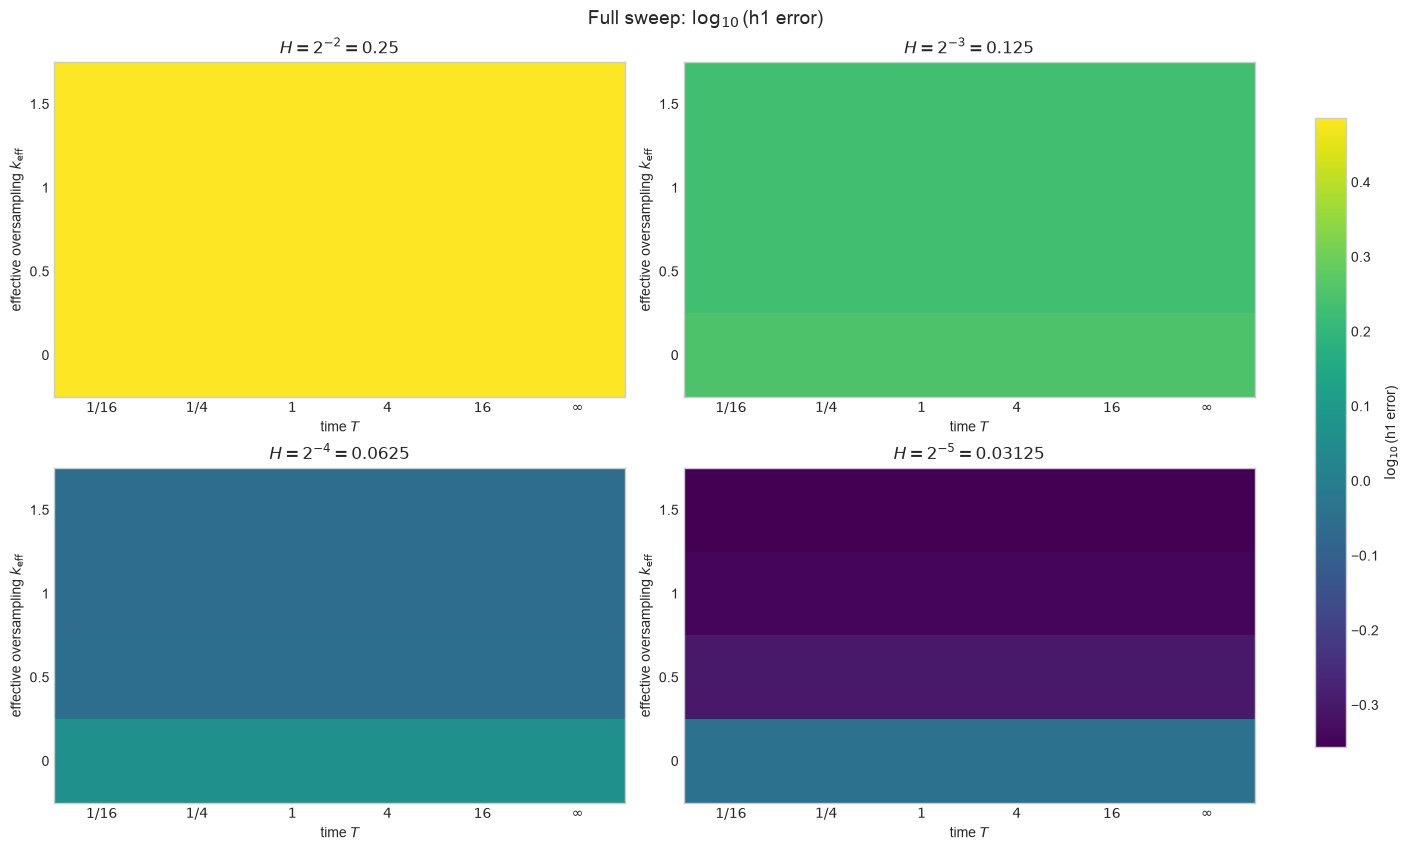

In [4]:
def plot_error_heatmap(data, error="h1_error", ncols=2):
    d = _clean(data, error)
    r_values = sorted(d["r"].unique())
    k_values = sorted(d["k_effective"].unique())
    finite_times = sorted(d.loc[np.isfinite(d["T"]), "T"].unique())
    times = finite_times + ([np.inf] if np.isinf(d["T"]).any() else [])
    time_index = {T: i for i, T in enumerate(finite_times)}

    nrows = math.ceil(len(r_values) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(7 * ncols, 4.2 * nrows), squeeze=False,
        layout="constrained",
    )
    axes = axes.ravel()
    log_error = np.log10(d[error])
    norm = Normalize(log_error.min(), log_error.max())
    image = None

    for ax, r in zip(axes, r_values):
        subset = d[d["r"].eq(r)].copy()
        subset["time_index"] = subset["T"].map(
            lambda T: len(finite_times) if np.isinf(T) else time_index[T]
        )
        table = subset.pivot_table(
            index="k_effective", columns="time_index", values=error, aggfunc="mean"
        ).reindex(index=k_values, columns=range(len(times)))
        image = ax.imshow(
            np.log10(table.to_numpy()), origin="lower", aspect="auto",
            cmap="viridis", norm=norm,
        )
        ax.set_xticks(range(len(times)), [rf"${_time_label(T)}$" for T in times])
        ax.set_yticks(range(len(k_values)), [f"{k:g}" for k in k_values])
        ax.set_xlabel(r"time $T$")
        ax.set_ylabel(r"effective oversampling $k_{\mathrm{eff}}$")
        ax.set_title(rf"$H=2^{{-{r}}}={2.0 ** (-r):g}$")
        ax.grid(False)

    _remove_unused_axes(fig, axes, len(r_values))
    fig.suptitle(rf"Full sweep: $\log_{{10}}$({error.replace('_', ' ')})", fontsize=14)
    if image is not None:
        fig.colorbar(
            image, ax=list(axes[:len(r_values)]), shrink=0.85,
            label=rf"$\log_{{10}}$({error.replace('_', ' ')})",
        )
    return fig


plot_error_heatmap(data, ERROR);

## Error versus coarse mesh size $H$

Each panel fixes time; curves compare oversampling ratios. This is the main view for spatial convergence and shows whether the observed behavior changes with $T$ and $k$.

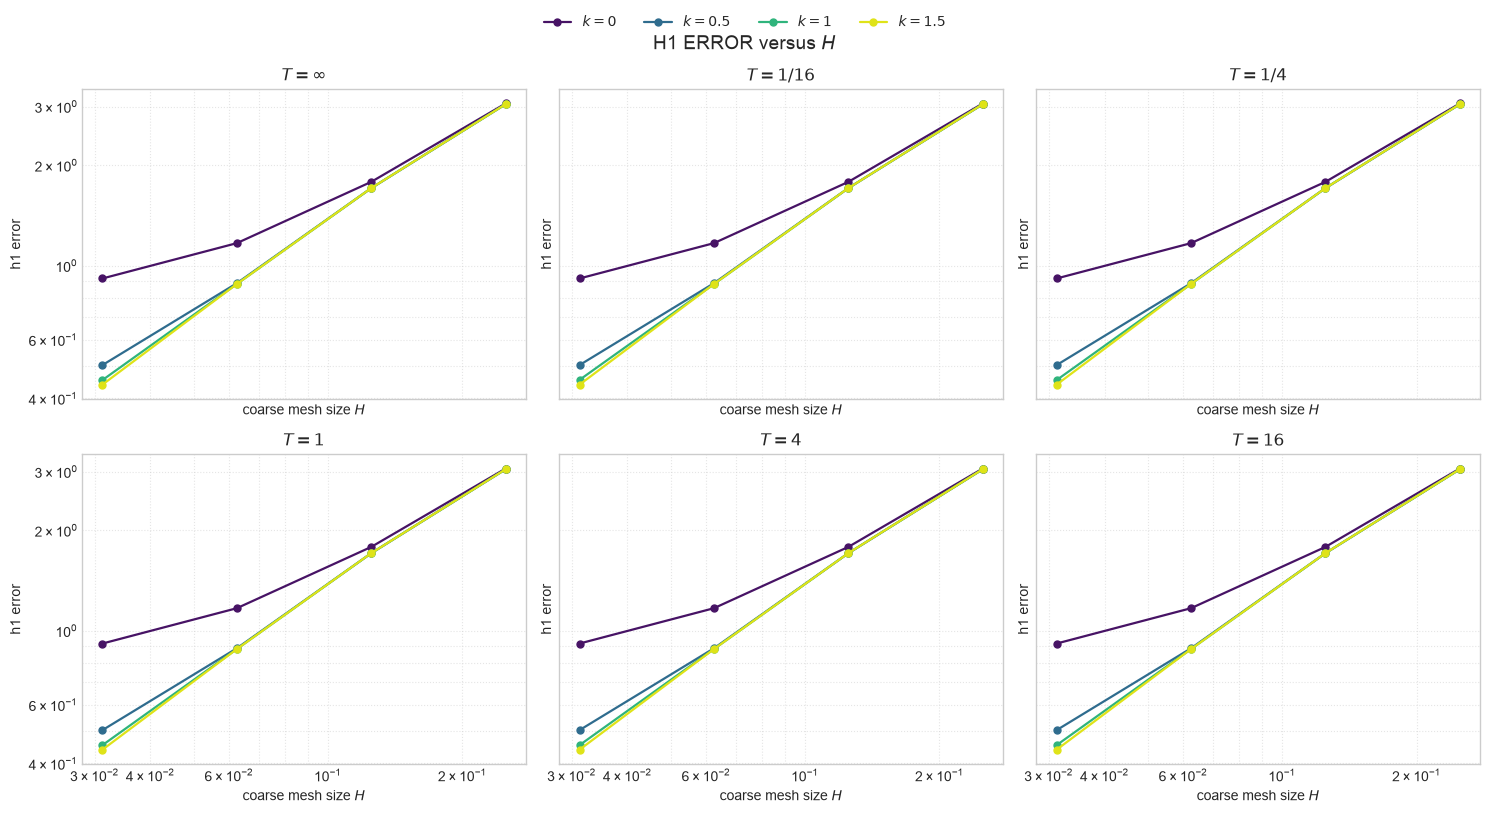

In [5]:
def plot_error_vs_H(data, error="h1_error", times=None, ncols=3):
    d = _clean(data, error)
    times = SELECTED_TIMES if times is None else times
    k_values = sorted(d["k"].unique())
    colors = dict(zip(k_values, plt.cm.viridis(np.linspace(0.05, 0.95, len(k_values)))))
    nrows = math.ceil(len(times) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(5 * ncols, 4 * nrows),
        squeeze=False, sharex=True, sharey=True,
    )
    axes = axes.ravel()

    for ax, T in zip(axes, times):
        for k, group in _at_time(d, T).groupby("k"):
            group = group.sort_values("H")
            ax.loglog(
                group["H"], group[error], marker="o", color=colors[k],
                linewidth=1.6, markersize=5, label=rf"$k={k:g}$",
            )
        ax.set_title(rf"$T={_time_label(T)}$")
        ax.set_xlabel(r"coarse mesh size $H$")
        ax.set_ylabel(error.replace("_", " "))
        ax.grid(True, which="both", linestyle=":", alpha=0.5)

    _remove_unused_axes(fig, axes, len(times))
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=len(k_values), bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(rf"{error.replace('_', ' ').upper()} versus $H$", fontsize=14)
    fig.tight_layout()
    return fig


plot_error_vs_H(data, ERROR, times=SELECTED_TIMES);

## Error versus oversampling

Each panel fixes $H$. The horizontal axis is the effective ratio after integer layer truncation, $k_{\mathrm{eff}}=\text{num layers}/2^{6-r}$.

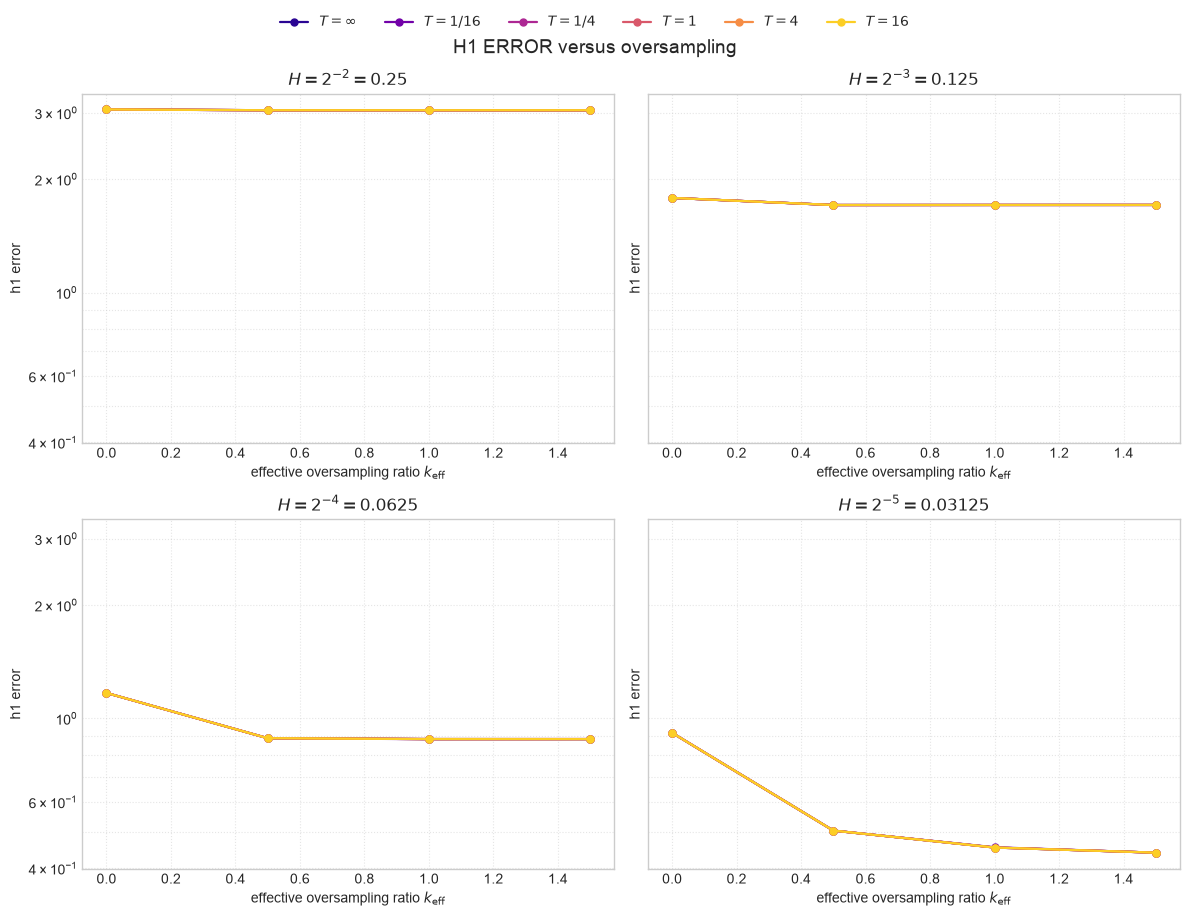

In [6]:
def plot_error_vs_oversampling(data, error="h1_error", times=None, ncols=2):
    d = _clean(data, error)
    times = SELECTED_TIMES if times is None else times
    r_values = sorted(d["r"].unique())
    colors = dict(zip(times, plt.cm.plasma(np.linspace(0.05, 0.9, len(times)))))
    nrows = math.ceil(len(r_values) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(6 * ncols, 4.5 * nrows),
        squeeze=False, sharey=True,
    )
    axes = axes.ravel()

    for ax, r in zip(axes, r_values):
        subset = d[d["r"].eq(r)]
        for T in times:
            group = _at_time(subset, T).sort_values("k_effective")
            if group.empty:
                continue
            ax.semilogy(
                group["k_effective"], group[error], marker="o", color=colors[T],
                linewidth=1.6, markersize=5, label=rf"$T={_time_label(T)}$",
            )
        ax.set_title(rf"$H=2^{{-{r}}}={2.0 ** (-r):g}$")
        ax.set_xlabel(r"effective oversampling ratio $k_{\mathrm{eff}}$")
        ax.set_ylabel(error.replace("_", " "))
        ax.grid(True, which="both", linestyle=":", alpha=0.5)

    _remove_unused_axes(fig, axes, len(r_values))
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=len(times), bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(rf"{error.replace('_', ' ').upper()} versus oversampling", fontsize=14)
    fig.tight_layout()
    return fig


plot_error_vs_oversampling(data, ERROR, times=SELECTED_TIMES);

## Error versus time $T$

Solid curves use finite $T$. A dashed line of the same color is the elliptic result at $T=\infty$, so this view shows whether the parabolic result approaches the static corrector.

> The current CSV uses `Nt=1`, hence $\Delta t=T$. This is a smoke test, not a clean convergence experiment in $T$: changing $T$ also changes the backward-Euler error. For a formal experiment, fix $\Delta t$ and use $N_t=\lceil T/\Delta t\rceil$.

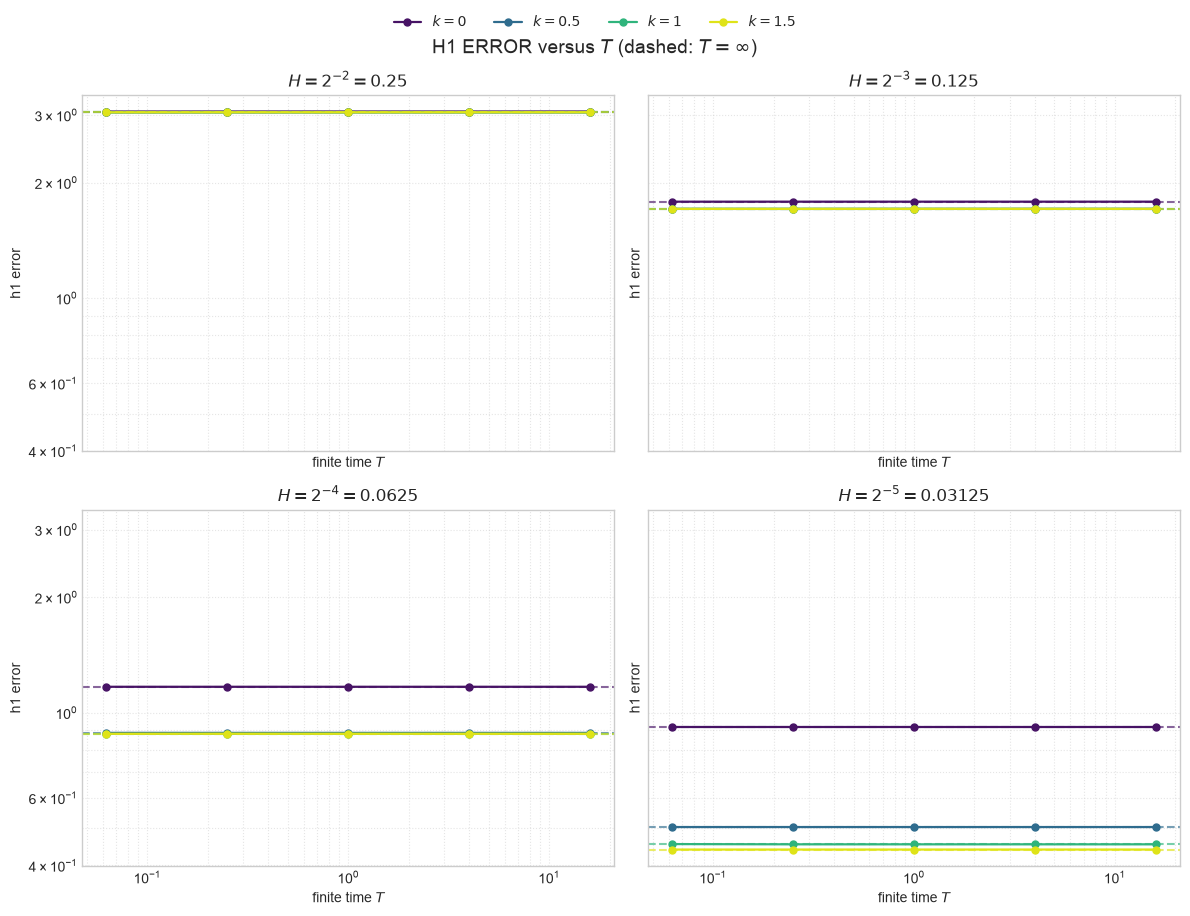

In [7]:
def plot_error_vs_T(data, error="h1_error", ncols=2):
    d = _clean(data, error)
    r_values = sorted(d["r"].unique())
    k_values = sorted(d["k"].unique())
    colors = dict(zip(k_values, plt.cm.viridis(np.linspace(0.05, 0.95, len(k_values)))))
    nrows = math.ceil(len(r_values) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(6 * ncols, 4.5 * nrows),
        squeeze=False, sharex=True, sharey=True,
    )
    axes = axes.ravel()

    for ax, r in zip(axes, r_values):
        subset = d[d["r"].eq(r)]
        for k, group in subset.groupby("k"):
            finite = group[np.isfinite(group["T"])].sort_values("T")
            elliptic = group[np.isinf(group["T"])]
            if not finite.empty:
                ax.loglog(
                    finite["T"], finite[error], marker="o", color=colors[k],
                    linewidth=1.6, markersize=5, label=rf"$k={k:g}$",
                )
            if not elliptic.empty:
                ax.axhline(
                    elliptic[error].iloc[0], color=colors[k], linestyle="--", alpha=0.65
                )
        ax.set_title(rf"$H=2^{{-{r}}}={2.0 ** (-r):g}$")
        ax.set_xlabel(r"finite time $T$")
        ax.set_ylabel(error.replace("_", " "))
        ax.grid(True, which="both", linestyle=":", alpha=0.5)

    _remove_unused_axes(fig, axes, len(r_values))
    handles, labels = axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc="upper center", ncol=len(k_values), bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(
        rf"{error.replace('_', ' ').upper()} versus $T$ (dashed: $T=\infty$)", fontsize=14
    )
    fig.tight_layout()
    return fig


plot_error_vs_T(data, ERROR);